In [48]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [49]:
from utils import *

Synthetic data testing of the implemented class

In [50]:
# Parameters
d , n , q = 3 , 10000 , 4

# Generate synthetic input data
X = np.random.randn(d, n)

# Generate custom rule
W_true = np.random.randn(q, d + 1)
Xt_temp = np.vstack([X, np.ones((1, n))])
logits = W_true @ Xt_temp + np.random.randn(q, n) * 0.3

# Generate targets
y = np.argmax(logits, axis=0)

# Train/test split
indices = np.random.permutation(n)
split = int(0.8 * n)

train_idx, test_idx = indices[:split], indices[split:]

X_train, y_train = X[:, train_idx], y[train_idx]
X_test, y_test = X[:, test_idx], y[test_idx]

# Fitting the classifier
clf = Classifier(lr=0.1, epochs=50, num_class=q, batch_size=128)
a, b = clf.fit(X_train, y_train,return_metrics=True)

# Test evaluation
y_test_pred = clf.classify(X_test)
test_acc = 100 * clf.accuracy(y_test, y_test_pred)
print(f"Test Accuracy: {test_acc:.2f}%")

Epochs 1 | Loss 0.5761 | Accuracy 87.26 %
Epochs 11 | Loss 0.3004 | Accuracy 89.36 %
Epochs 21 | Loss 0.2710 | Accuracy 89.70 %
Epochs 31 | Loss 0.2588 | Accuracy 89.71 %
Epochs 41 | Loss 0.2522 | Accuracy 89.70 %
Test Accuracy: 88.50%


In [51]:
q = 10
# Download MNIST dataset
train = MNIST(root="./data", train=True, download=True)
test = MNIST(root="./data", train=False, download=True)

# Convert to ndarray and normalize
X_train = train.data.numpy().astype(np.float32) / 255.0
X_test = test.data.numpy().astype(np.float32) / 255.0

y_train = train.targets.numpy().astype(np.int64)
y_test = test.targets.numpy().astype(np.int64)

# Flatten
X_train = X_train.reshape(-1 , 784).T
X_test = X_test.reshape(-1 , 784).T

In [52]:
classifier = Classifier( lr = 0.01 , epochs = 200 , num_class = q , lam = 0.0, batch_size = 128 )
idx = np.random.choice( np.arange(X_train.shape[-1]) , size = X_train.shape[-1] , replace=False )
loss_curve, accuracy_curve = classifier.fit( X_train[:,idx] , y_train[idx] , return_metrics=True)

Epochs 1 | Loss 0.8215 | Accuracy 83.94 %
Epochs 11 | Loss 0.3910 | Accuracy 89.51 %
Epochs 21 | Loss 0.3482 | Accuracy 90.46 %
Epochs 31 | Loss 0.3280 | Accuracy 90.92 %
Epochs 41 | Loss 0.3159 | Accuracy 91.20 %
Epochs 51 | Loss 0.3074 | Accuracy 91.51 %
Epochs 61 | Loss 0.3011 | Accuracy 91.66 %
Epochs 71 | Loss 0.2961 | Accuracy 91.79 %
Epochs 81 | Loss 0.2920 | Accuracy 91.87 %
Epochs 91 | Loss 0.2886 | Accuracy 91.96 %
Epochs 101 | Loss 0.2857 | Accuracy 92.03 %
Epochs 111 | Loss 0.2832 | Accuracy 92.11 %
Epochs 121 | Loss 0.2809 | Accuracy 92.19 %
Epochs 131 | Loss 0.2789 | Accuracy 92.28 %
Epochs 141 | Loss 0.2772 | Accuracy 92.32 %
Epochs 151 | Loss 0.2755 | Accuracy 92.36 %
Epochs 161 | Loss 0.2740 | Accuracy 92.41 %
Epochs 171 | Loss 0.2727 | Accuracy 92.45 %
Epochs 181 | Loss 0.2715 | Accuracy 92.48 %
Epochs 191 | Loss 0.2703 | Accuracy 92.53 %


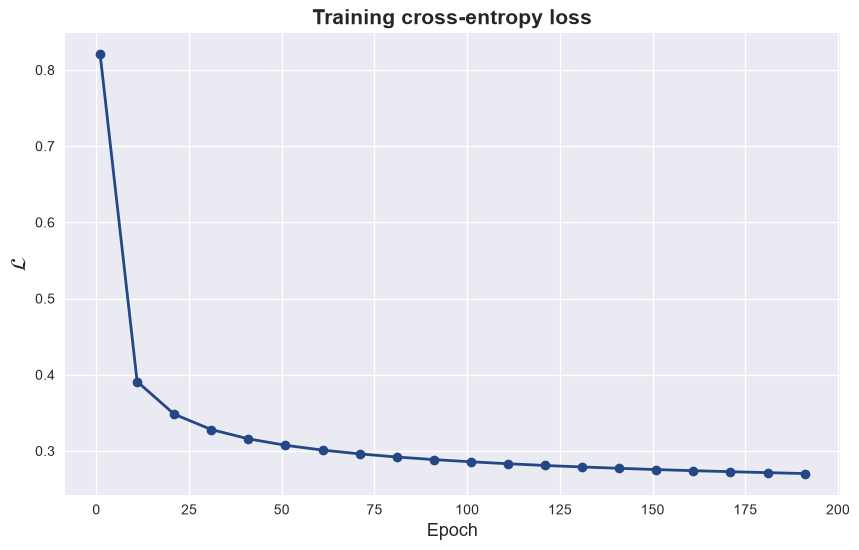

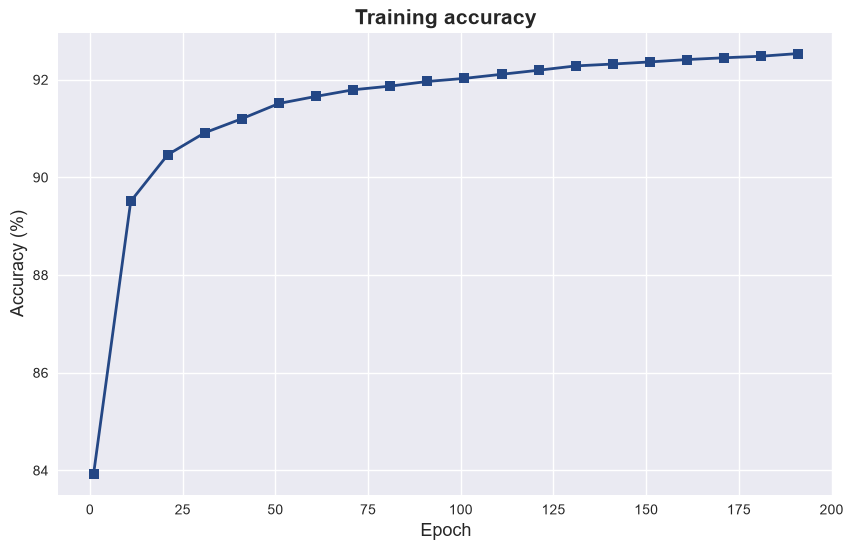

In [71]:
plt.style.use('seaborn-v0_8')
os.makedirs('./figures',exist_ok=True)

plt.figure(figsize=(10,6))
plt.plot( loss_curve, 'o-', linewidth = 2 ,color = '#244785' )
plt.xlabel('Epoch',fontsize=13)
plt.ylabel(r'$\mathcal{L}$',fontsize=15)
plt.grid(True)
plt.title('Training cross-entropy loss',fontsize = 15, fontweight='bold')
plt.savefig('./figures/MNIST_training_loss')
plt.show()

plt.figure(figsize=(10,6))
plt.plot( accuracy_curve , 's-', linewidth = 2 ,color = '#244785')
plt.xlabel('Epoch',fontsize=13)
plt.ylabel('Accuracy (%)',fontsize=13)
plt.grid(True)
plt.title('Training accuracy',fontsize = 15, fontweight='bold')
plt.savefig('./figures/MNIST_training_accuracy.png' , )
plt.show()

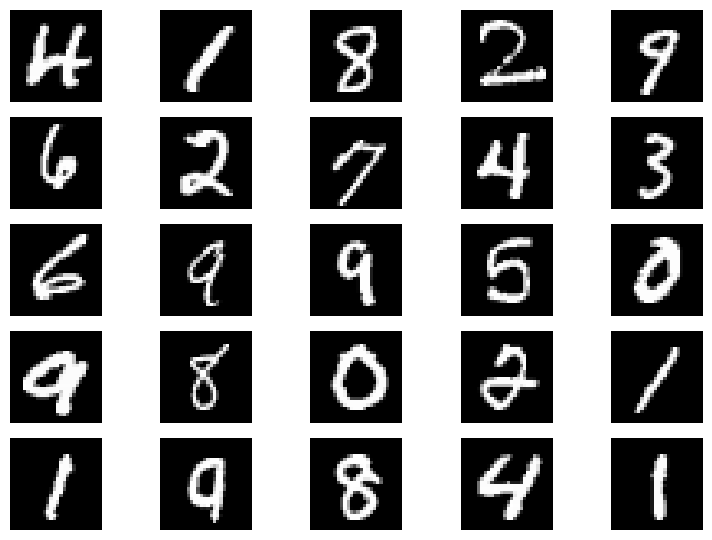

In [64]:
fig, axes = plt.subplots(5,5)
imgs = np.random.choice(X_train.shape[1], size = 25)
for i,ax in enumerate(axes.flatten()):
    img = X_train[ : , imgs[i] ].reshape(28,-1)
    ax.imshow(img,cmap='gray')
    ax.axis('off')
plt.tight_layout()
plt.savefig('./figures/mnist_example.png')
plt.show()

In [65]:
y_test_pred = classifier.classify(X_test)
test_accuracy = 100 * classifier.accuracy(y_test,y_test_pred)
print(f'Test accuracy: {test_accuracy:.2f} %')

Test accuracy: 92.31 %


In [66]:
correct = [ k for k , el in enumerate(y_test) if y_test_pred[k] == el ]
wrong = [ k for k , el in enumerate(y_test) if y_test_pred[k] != el ]

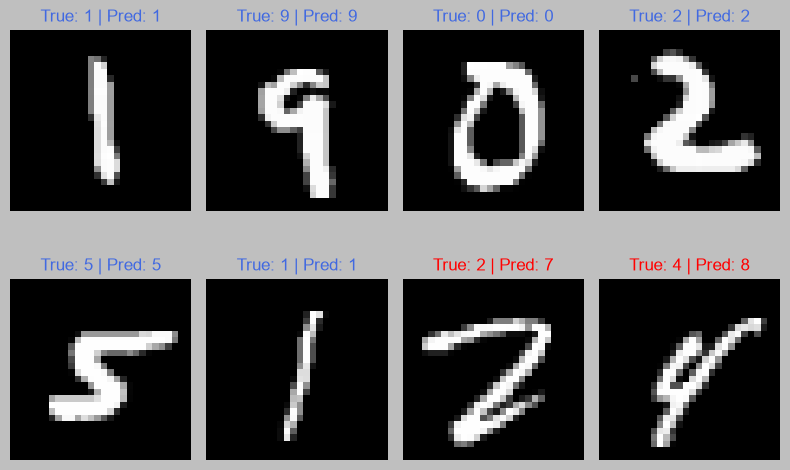

In [70]:
plt.style.use('grayscale')
fig, axes = plt.subplots(2,4)

imgs = np.concat( [np.random.choice( correct, size = 6 ) , np.random.choice(wrong , size = 2)] )

for k,ax in enumerate(axes.flatten()):
    x_plot = X_test[:, imgs[k] ].reshape(28,-1)
    
    ax.imshow(x_plot)

    col = 'royalblue' if int(y_test[ imgs[k] ]) == int(y_test_pred[ imgs[k] ]) else 'red'
    
    ax.set_title(f'True: {y_test[imgs[k]]} | Pred: {y_test_pred[imgs[k]]}', color = col )
    ax.axis('off')

plt.tight_layout()
plt.savefig('./figures/classification_results.png')
plt.show()